In [1]:
!pip install -q plotnine

StatementMeta(, 0420fb93-fb9a-4e39-8a5f-95309296ae9f, 3, Finished, Available, Finished)

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from pyspark.sql.functions import col, lit, to_timestamp, date_trunc, avg
from plotnine import (
    ggplot, aes, geom_line, labs, theme, element_text, element_rect, theme_minimal, 
    ylim, coord_cartesian, geom_hline, facet_wrap, scale_x_datetime, scale_y_continuous 
)


StatementMeta(, 0420fb93-fb9a-4e39-8a5f-95309296ae9f, 34, Finished, Available, Finished)

In [33]:
# ================================== EQUIPMENTS ================================== 
data_equipments = {
    "Equipment": [
        "TRH380", "TRH342", "TRH343", "TRH361", "TRH362", "TRH363", "TRH364",
        "TRH374", "TRH376", "TRH377", "TRH378", "TRH379", "TRH382", "TRH385",
        "TRH386", "TRH390", "TRH391", "TRH392", "TRH394", "TRH395", "TRH396",
        "TRH398", "TRH340", "TRH344", "TRH345", "TRH346", "TRH359", "TRH360",
        "TRH365", "TRH366", "TRH367", "TRH368", "TRH369", "TRH370", "TRH371",
        "TRH372", "TRH373", "TRH375", "TRH381", "TRH383", "TRH384", "TRH387",
        "TRH388", "TRH389", "TRH393", "TRH399", "TRH347"
    ],
    "ClassType": [
        "Cat 793C", "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793D",
        "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C",
        "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C",
        "Cat 793C", "Cat 793C", "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793D",
        "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793C", "Cat 793C",
        "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C",
        "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793D"
    ]
}

# Create DataFrame
df_source_equipments = pd.DataFrame(data_equipments)

# Group by 'class_type' and aggregate equipment into lists
df_equipments = df_source_equipments.groupby("ClassType")["Equipment"].apply(list).reset_index()
df_equipments.columns = ["ClassType", "Equipment"]

# ================================== SENSORS ==================================
data_measurements = [
    "Lt Front Brake Temperature",
    "Lt Rear Brake Temperature",
    "Rt Front Brake Temperature",
    "Rt Rear Brake Temperature",
]

StatementMeta(, 0420fb93-fb9a-4e39-8a5f-95309296ae9f, 35, Finished, Available, Finished)

In [34]:
def aggregate_data(df, time_unit):
    """
    Aggregates the data based on the given time unit.

    Parameters:
        df (DataFrame): Filtered PySpark DataFrame.
        time_unit (str): One of ["minute", "hour", "day", "week", "month"].

    Returns:
        DataFrame: Aggregated DataFrame.
    """
    if time_unit == "minute":
        # No aggregation, keep original values
        return df.select("Nombre_Camion", "Categoria", "Nombre_Tag", "Fecha_Hora", "Valor")

    # Define truncation level
    trunc_time = date_trunc(time_unit, col("Fecha_Hora"))

    return (df
        .groupBy("Nombre_Camion", "Categoria", "Nombre_Tag", trunc_time.alias("Fecha_Hora"))
        .agg(avg("Valor").alias("Valor"))
    )

StatementMeta(, 0420fb93-fb9a-4e39-8a5f-95309296ae9f, 36, Finished, Available, Finished)

In [35]:
def execute_brake_temperature(source_df, df_equipments, start_date, end_date, show_mean, y_breaks):
    """
    Generate line charts for brake temperature over time for various equipments.

    This function processes a source DataFrame containing sensor measurements and creates a separate line chart 
    for each equipment specified in the df_equipments DataFrame. For each equipment, the function:
      - Filters the source data by truck name, sensor tags, and a given datetime range.
      - Converts the filtered Spark DataFrame to a pandas DataFrame for further processing.
      - Renames and cleans the dataset (e.g., converting datetime strings to datetime objects).
      - Computes summary statistics (mean brake temperature per equipment) and merges these values into the dataset.
      - Generates a line chart using ggplot with facets for each equipment, customized x/y-axis scales, limits, and themes.
      - Optionally adds a horizontal dashed line to indicate the mean value if show_mean is True.
      - Adjusts figure size and formatting based on the number of equipments.
      - Saves the resulting plot as a JPEG file to a specified directory.

    Parameters:
      source_df (DataFrame): The primary dataset (e.g., a Spark DataFrame) containing sensor data.
      df_equipments (DataFrame): A DataFrame that specifies equipments and associated metadata.
      start_date (str): Start datetime as a string in the format "YYYY-MM-DD HH:MM:SS".
      end_date (str): End datetime as a string in the format "YYYY-MM-DD HH:MM:SS".
      show_mean (bool): Whether to add a horizontal line showing the mean value for each equipment.
      y_breaks (list): List of y-axis tick positions to be used in the plot.

    Returns:
      figures (list): List of matplotlib figure objects generated for each equipment.
    """
    figures = []
    # Generate a timestamp to uniquely identify the output files (e.g., "2025-03-19_14-30-45")
    timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
    # Convert start_date and end_date strings to datetime objects for filtering
    start_date_dt = datetime.strptime(start_date, "%Y-%m-%d %H:%M:%S")
    end_date_dt = datetime.strptime(end_date, "%Y-%m-%d %H:%M:%S")
    
    # Loop over each row in the df_equipments DataFrame, representing different equipment sets
    for index, row_equipment in df_equipments.iterrows():
        print(f"Class Type: {row_equipment['ClassType']}")
        
        # Filter source_df based on three conditions:
        # 1. 'Nombre_Camion' must be in the equipment list specified in current row.
        # 2. 'Nombre_Tag' must be in the global variable 'data_measurements' (assumed predefined).
        # 3. 'Fecha_Hora' must be between the specified start and end datetimes.
        df_filtered = source_df.filter(
            (col("Nombre_Camion").isin(row_equipment["Equipment"])) & 
            (col("Nombre_Tag").isin(data_measurements)) & 
            (col("Fecha_Hora").between(lit(start_date_dt), lit(end_date_dt))) 
        )
        
        # Convert the filtered Spark DataFrame to a pandas DataFrame for easier manipulation and plotting
        source_pandas_df = df_filtered.toPandas()
        # Select and rename relevant columns for clarity
        dataset = source_pandas_df[["Fecha_Hora", "Nombre_Camion", "Nombre_Tag", "Valor"]].copy()
        dataset.columns = ["Datetime", "Equipment", "Sensor", "Value"]
        original_dataset = dataset.copy()
        
        # Ensure that the 'Datetime' column is in proper datetime format
        dataset["Datetime"] = pd.to_datetime(dataset["Datetime"])
        # Optional: Remove rows with NaN values or filter out values outside a reasonable range
        # dataset = dataset.dropna(subset=["Value"])  
        # dataset = dataset[(dataset["Value"] >= 0) & (dataset["Value"] <= 150)]
        
        # Compute the mean brake temperature per equipment (similar to a group_by and summarise in R)
        mean_values = dataset.groupby("Equipment")["Value"].mean().reset_index()
        mean_values.rename(columns={"Value": "Mean_Value"}, inplace=True)
        # Merge the computed mean back into the dataset for use in plotting
        dataset = dataset.merge(mean_values, on="Equipment", how="left")
        
        row_count = len(dataset)
        print(f"Total rows: {row_count}")
        if row_count > 0:
            # Build the line chart using ggplot:
            # - x-axis is the datetime of the measurement.
            # - y-axis is the brake temperature ('Value').
            # - Different colors represent different sensors.
            # - facet_wrap splits the chart into subplots per equipment.
            line_chart = (
                ggplot(dataset, aes(x="Datetime", y="Value", color="Sensor"))
                + geom_line()
                + facet_wrap("~Equipment", ncol=3)  # Create facets (3 columns per row)
                + scale_x_datetime(
                    date_labels="%Y-%m-%d"  # Format datetime labels on the x-axis
                )
                + scale_y_continuous(
                    breaks=y_breaks  # Use provided y-axis tick positions
                )
                + coord_cartesian(ylim=(0, 150))  # Set y-axis limits from 0 to 150°C
                + theme_minimal() 
                + labs(
                    title=f"Brake Temperature - {row_equipment['ClassType']} ({start_date_dt.date()} - {end_date_dt.date()})",
                    x="Datetime",
                    y="Brake Temperature °C"
                )
                + theme(
                    figure_size=(12, 8),  # Define base figure size
                    axis_text_x=element_text(rotation=90, ha="right"),  # Rotate x-axis labels for clarity
                    panel_background=element_rect(fill="white"),
                    plot_background=element_rect(fill="white"),
                )
            )
            # Optionally add a dashed horizontal line representing the mean value if requested
            if show_mean:
                line_chart += geom_hline(aes(yintercept="Mean_Value"), dataset, color="black", linetype="dashed")

            # Draw the chart and retrieve the matplotlib figure object
            fig = line_chart.draw()
            fig.patch.set_visible(False)
            fig.patch.set_facecolor('white')
            
            # Determine figure height adjustment based on the number of equipments (improves readability)
            count_equipment = len(row_equipment["Equipment"])
            height_length = 1
            if count_equipment >= 30:
                height_length = 2
            elif (count_equipment >= 10) and (count_equipment < 30):
                height_length = 1.5 
            orig_width, orig_height = fig.get_size_inches() 
            new_height = orig_height * height_length 
            fig.set_size_inches(orig_width, new_height) 

            # Loop over all axes (each facet subplot) to adjust visual properties:
            for ax in fig.axes:
                ax.set_facecolor('white')
                # Create a secondary y-axis that shares the same x-axis
                ax2 = ax.twinx()
                # Ensure the twin y-axis has the same limits and ticks as the primary axis
                ax2.set_ylim(ax.get_ylim())
                ax2.set_yticks(y_breaks)
                ax2.tick_params(axis='y', labelsize=8)  # Set font size for secondary y-axis ticks
                # Remove all spines (borders) for a cleaner look
                for spine in ax.spines.values():
                    spine.set_visible(False)
                for spine in ax2.spines.values():
                    spine.set_visible(False)
                ax.tick_params(length=0)
                ax2.tick_params(length=0)

            # Append the figure to the list for later use or review
            figures.append(fig)
            # Save the figure to a JPEG file with a unique name based on class type and timestamp.
            fig.savefig(f"/lakehouse/default/Files/Images/Linechart_{row_equipment['ClassType']}_{timestamp}.jpeg", dpi=400)
    
    # Return all generated figures
    return figures


StatementMeta(, 0420fb93-fb9a-4e39-8a5f-95309296ae9f, 37, Finished, Available, Finished)

# Call data from source

In [36]:
source_df = spark.table("sensores_camiones")
source_df = source_df.withColumn("Fecha_Hora", to_timestamp(col("Fecha_Hora"), "yyyy-MM-dd HH:mm:ss"))
source_df = source_df.withColumn("Valor", col("Valor").cast("double"))

# Apply filtering: Only keep non-null values in 'Valor' that are between 0 and 150
filtered_df = source_df.filter((col("Valor").isNotNull()) & (col("Valor") >= 0) & (col("Valor") <= 150))

StatementMeta(, 0420fb93-fb9a-4e39-8a5f-95309296ae9f, 38, Finished, Available, Finished)

# This year until now

StatementMeta(, 0420fb93-fb9a-4e39-8a5f-95309296ae9f, 39, Finished, Available, Finished)

Class Type: Cat 793C
Total rows: 203040
Class Type: Cat 793D
Total rows: 115056


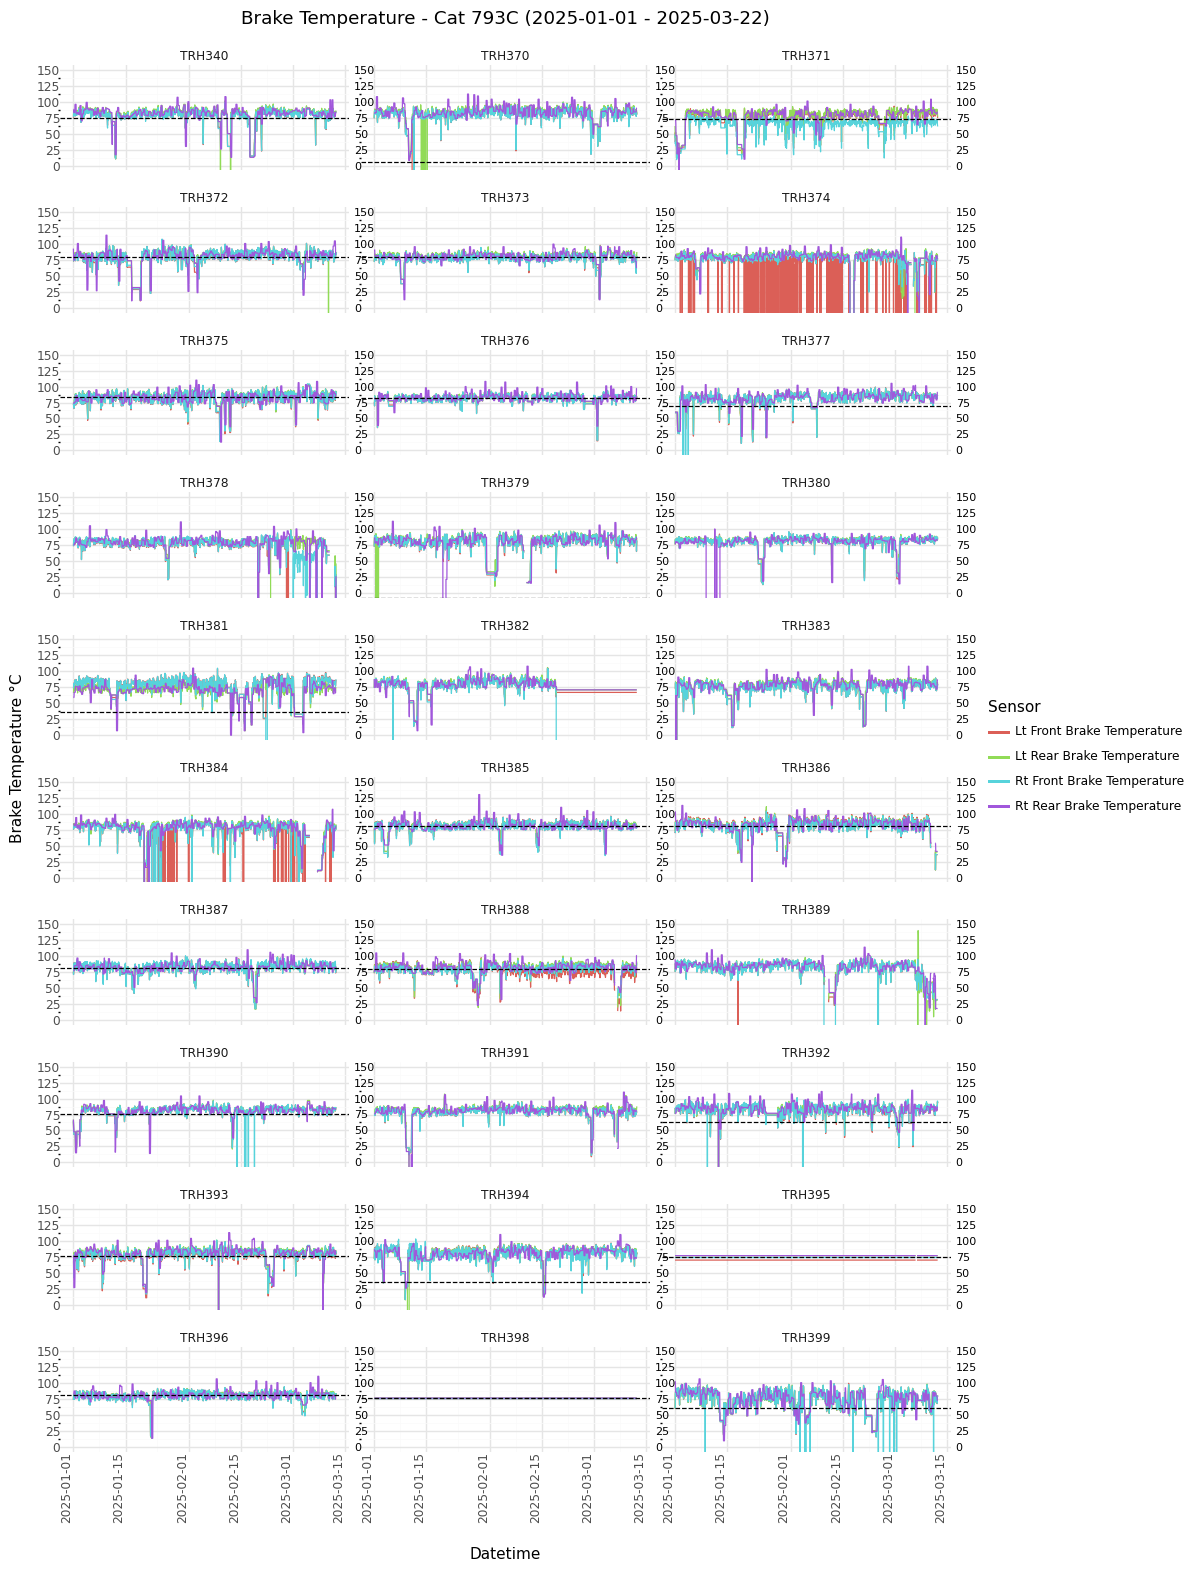

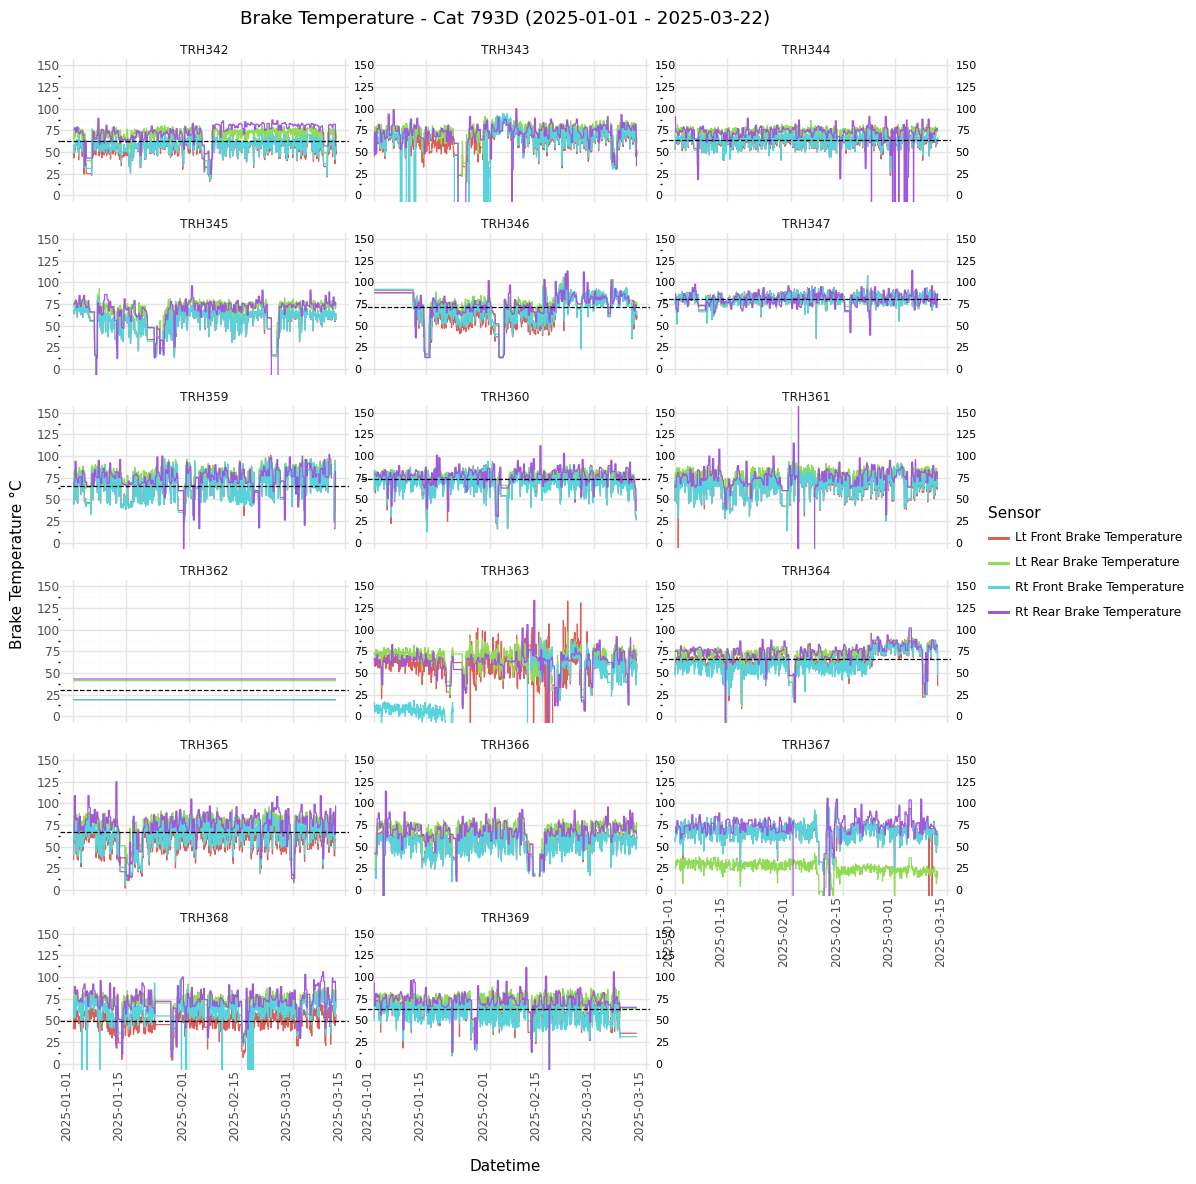

In [37]:
""" Example:
minute_source_df = aggregate_data(source_df, "minute") # Original data
hour_source_df = aggregate_data(source_df, "hour")
day_source_df = aggregate_data(source_df, "day")
week_source_df = aggregate_data(source_df, "week")
month_source_df = aggregate_data(source_df, "month")
"""
start_date = "2025-01-01 00:00:00"
end_date = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
hour_source_df = aggregate_data(source_df, "hour")
show_mean = True
y_breaks = [0, 25, 50, 75, 100, 125, 150]
returned_figures = execute_brake_temperature(hour_source_df, df_equipments, start_date, end_date, show_mean, y_breaks)
for fig in returned_figures:
    display(fig)

# Trend with hourly, daily, weekly and monthly data from January 2024 to now

### Hourly Trend

StatementMeta(, 0420fb93-fb9a-4e39-8a5f-95309296ae9f, 27, Finished, Available, Finished)

Class Type: Cat 793C
Total rows: 1257120
Class Type: Cat 793D
Total rows: 712368


/home/trusted-service-user/cluster-env/trident_env/lib/python3.11/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 159 rows containing missing values.


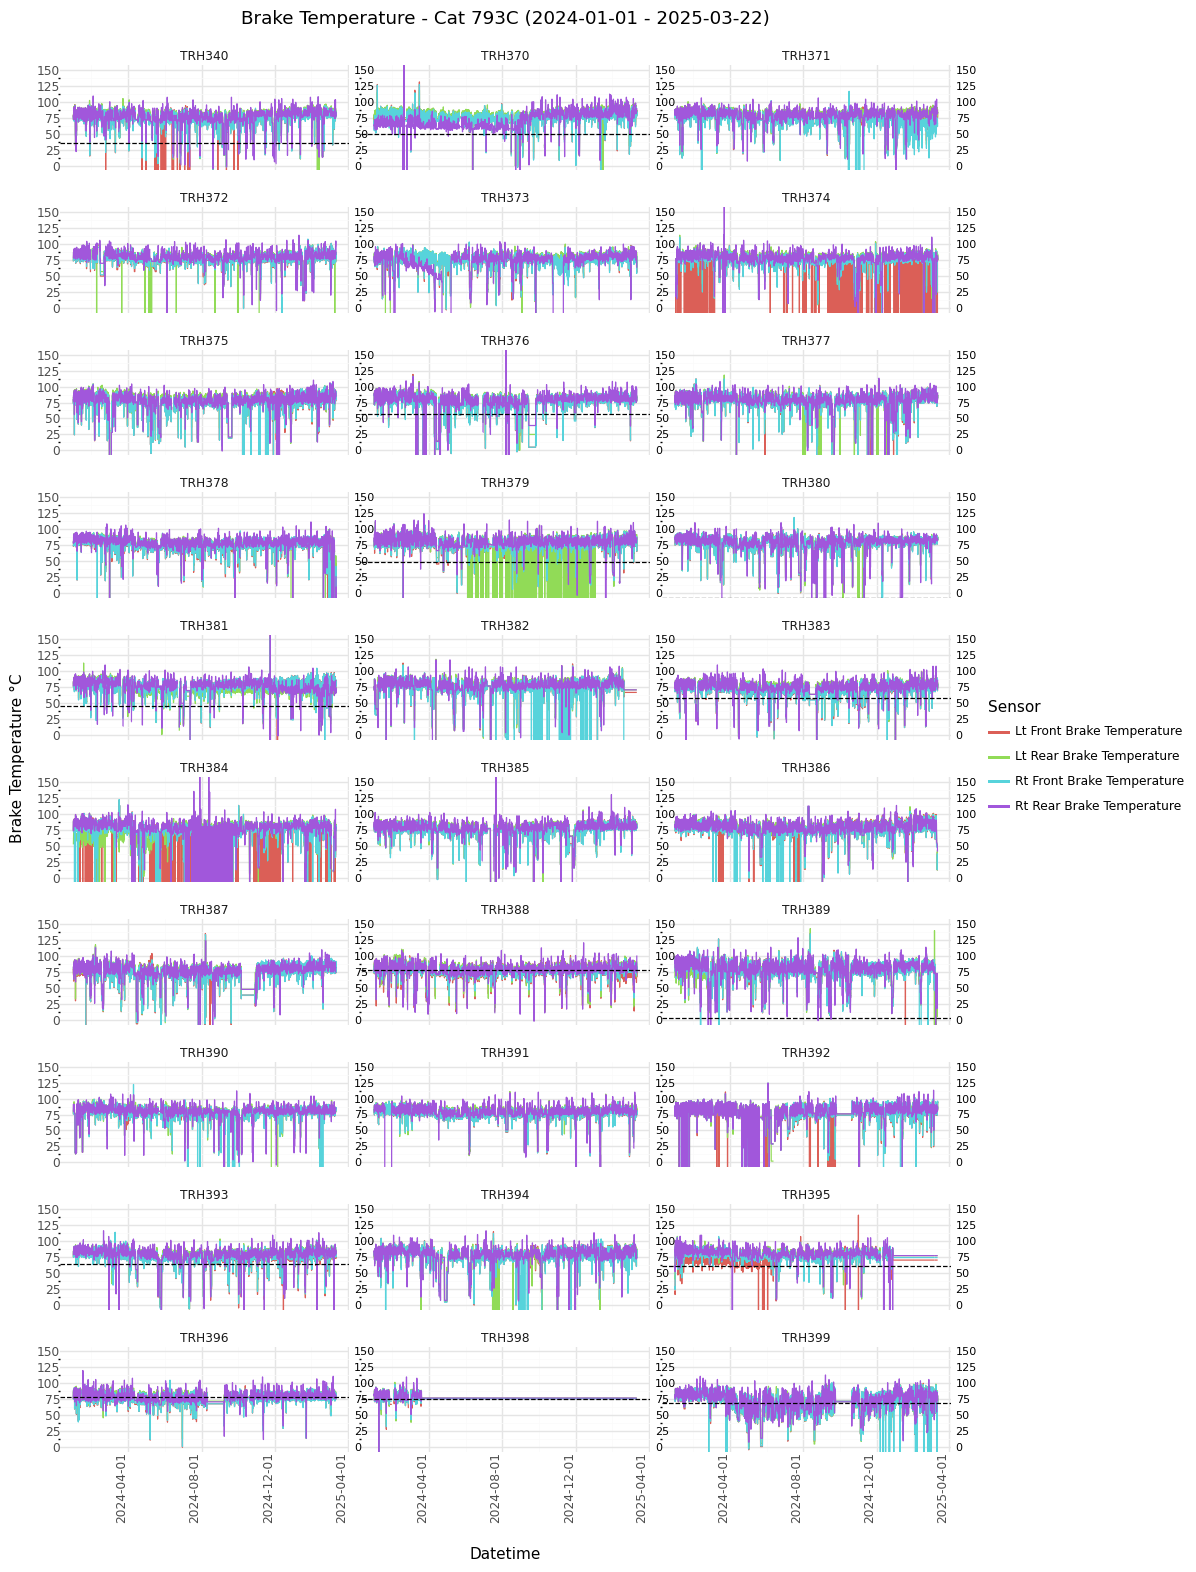

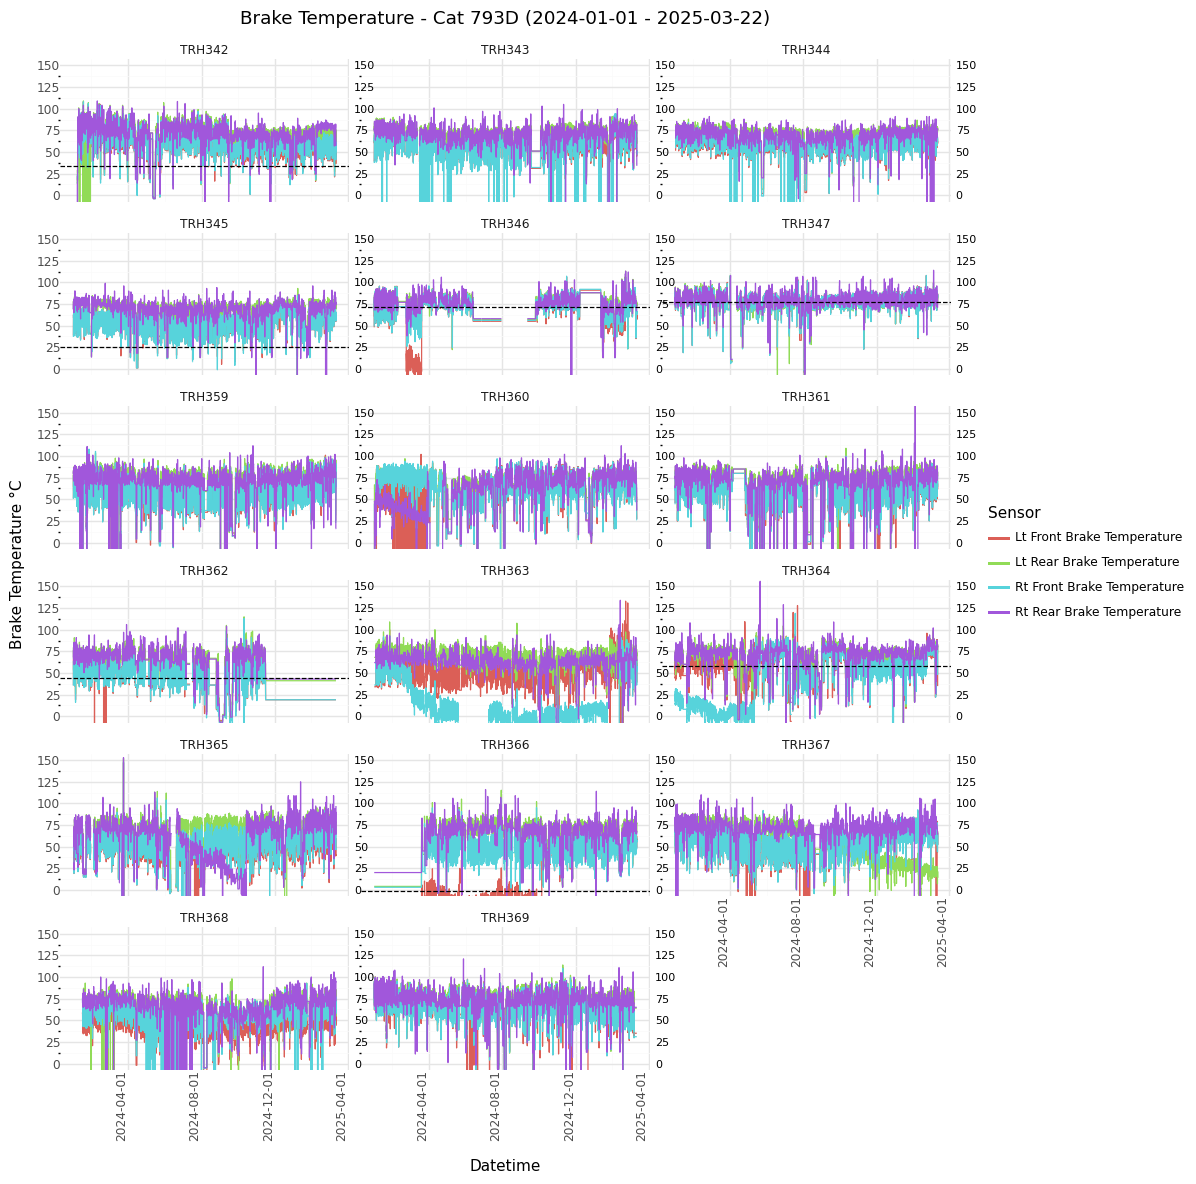

In [25]:
start_date = "2024-01-01 00:00:00"
end_date = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
hour_source_df = aggregate_data(source_df, "hour")
show_mean = True
y_breaks = [0, 25, 50, 75, 100, 125, 150]
returned_figures = execute_brake_temperature(hour_source_df, df_equipments, start_date, end_date, show_mean, y_breaks)
for fig in returned_figures:
    display(fig)

### Daily trend

StatementMeta(, 0420fb93-fb9a-4e39-8a5f-95309296ae9f, 28, Finished, Available, Finished)

Class Type: Cat 793C
Total rows: 52440
Class Type: Cat 793D


/home/trusted-service-user/cluster-env/trident_env/lib/python3.11/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 6 rows containing missing values.


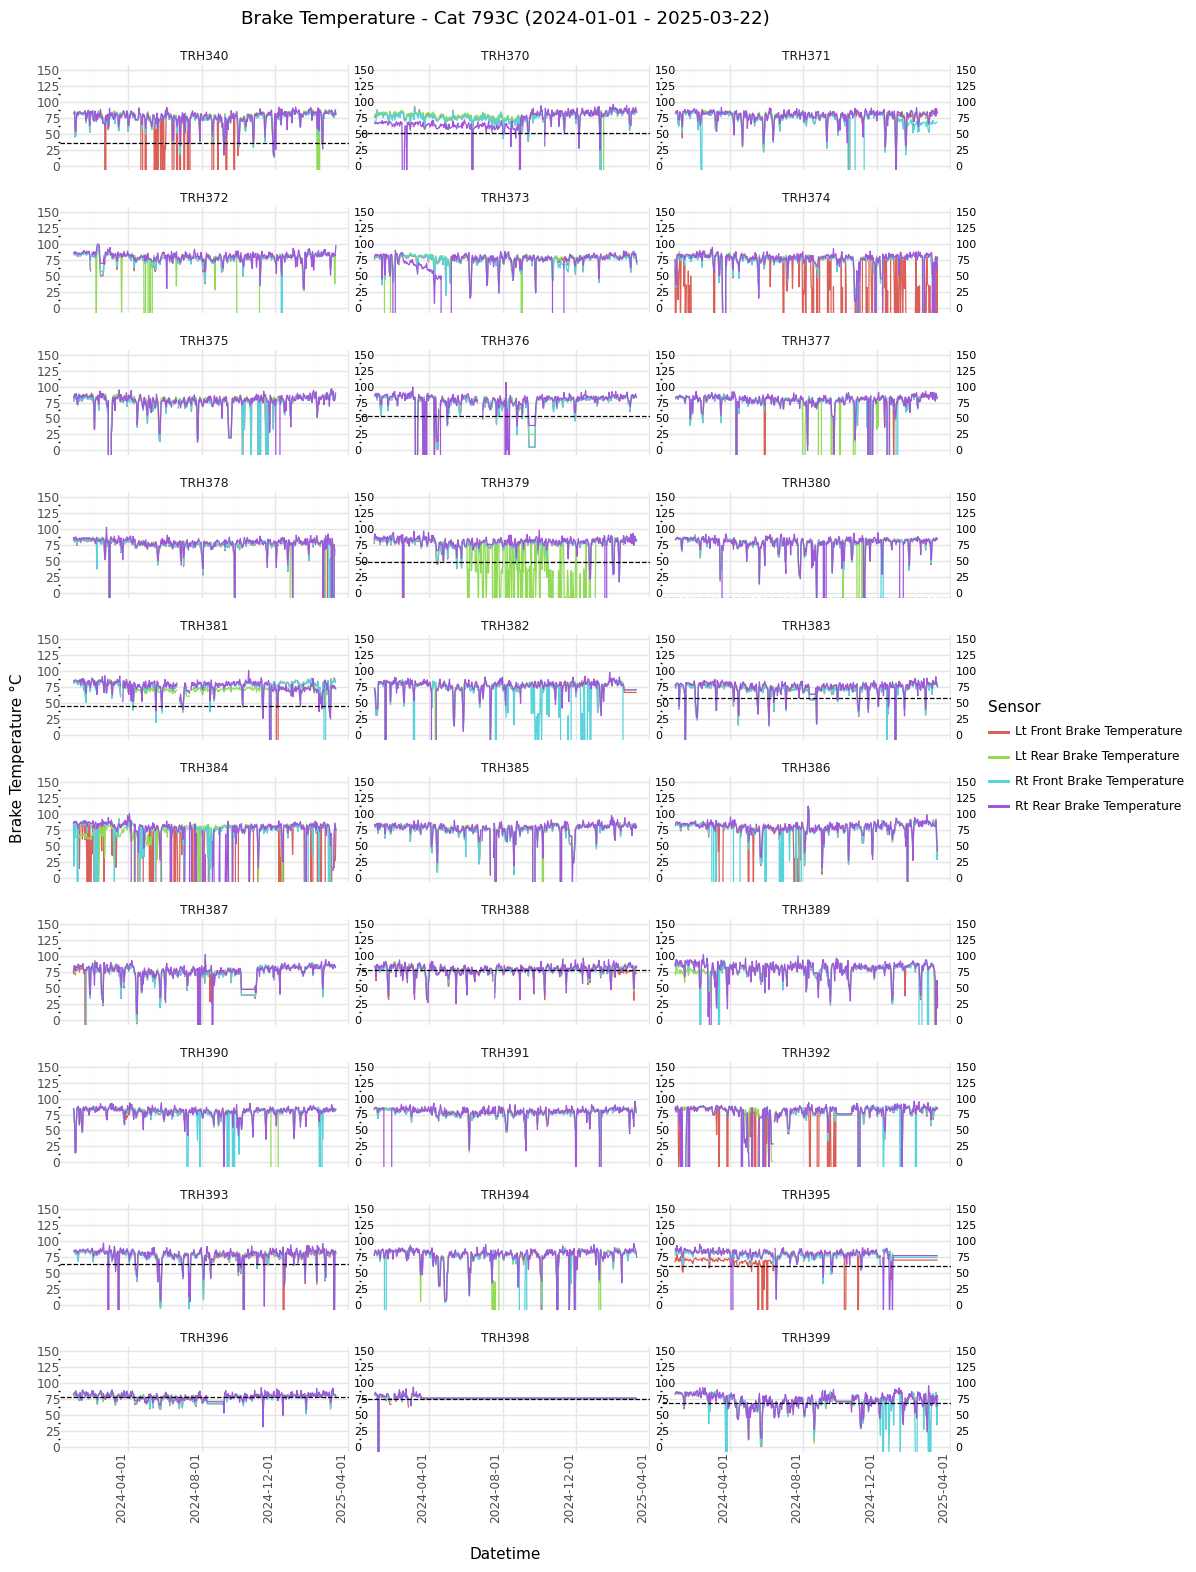

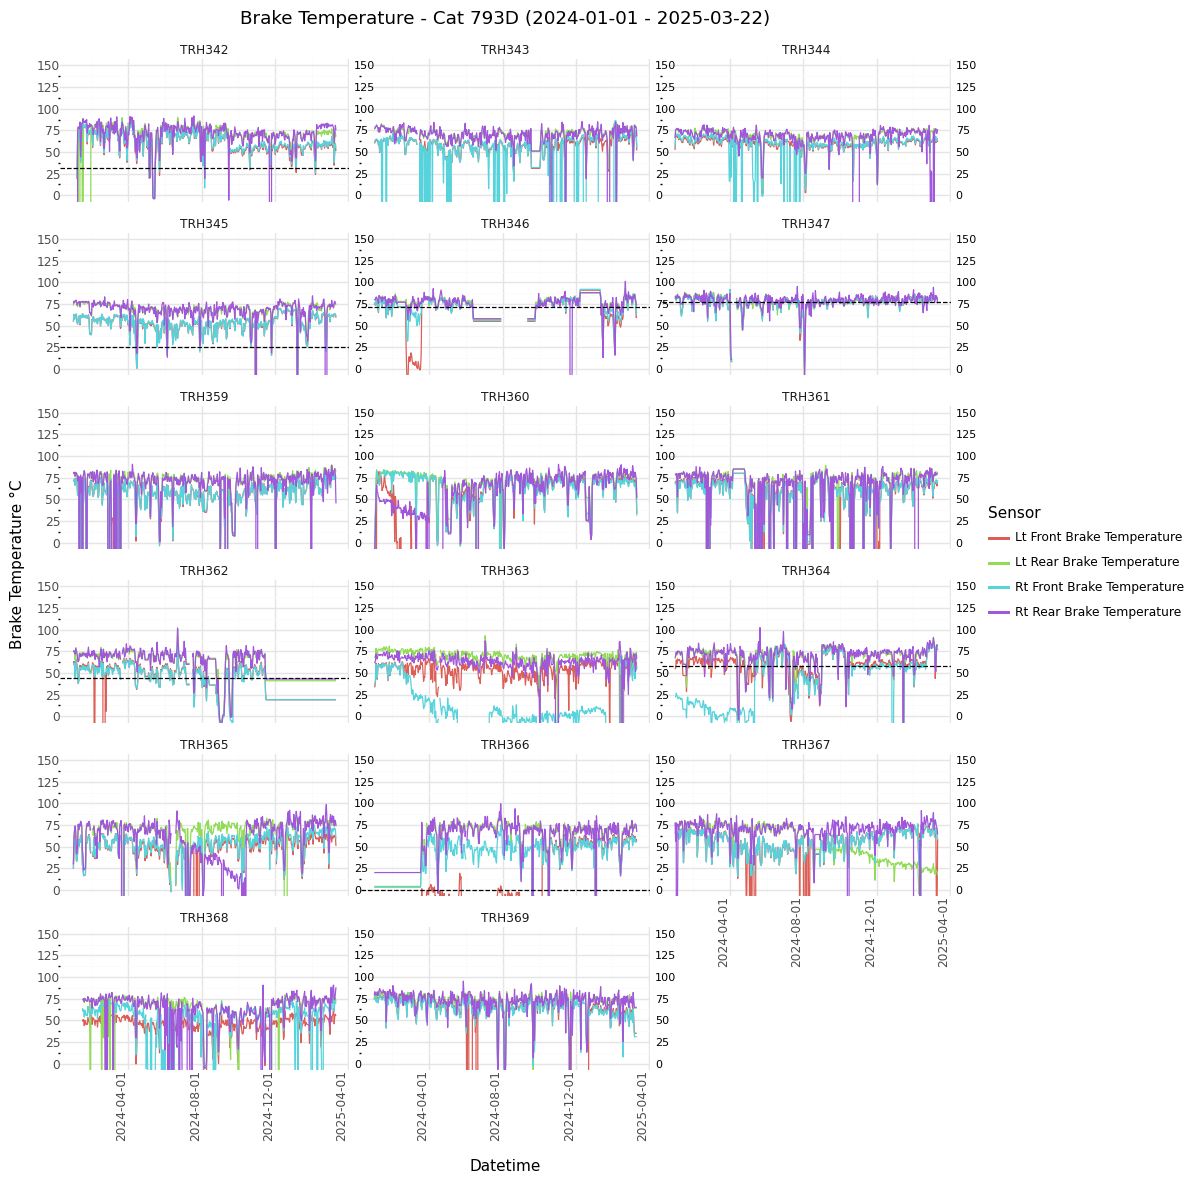

In [26]:
start_date = "2024-01-01 00:00:00"
end_date = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
day_source_df = aggregate_data(source_df, "day")
show_mean = True
y_breaks = [0, 25, 50, 75, 100, 125, 150]
returned_figures = execute_brake_temperature(day_source_df, df_equipments, start_date, end_date, show_mean, y_breaks)
for fig in returned_figures:
    display(fig)

### Weekly Trend

StatementMeta(, 0420fb93-fb9a-4e39-8a5f-95309296ae9f, 29, Finished, Available, Finished)

Class Type: Cat 793C
Total rows: 7560
Class Type: Cat 793D
Total rows: 4284


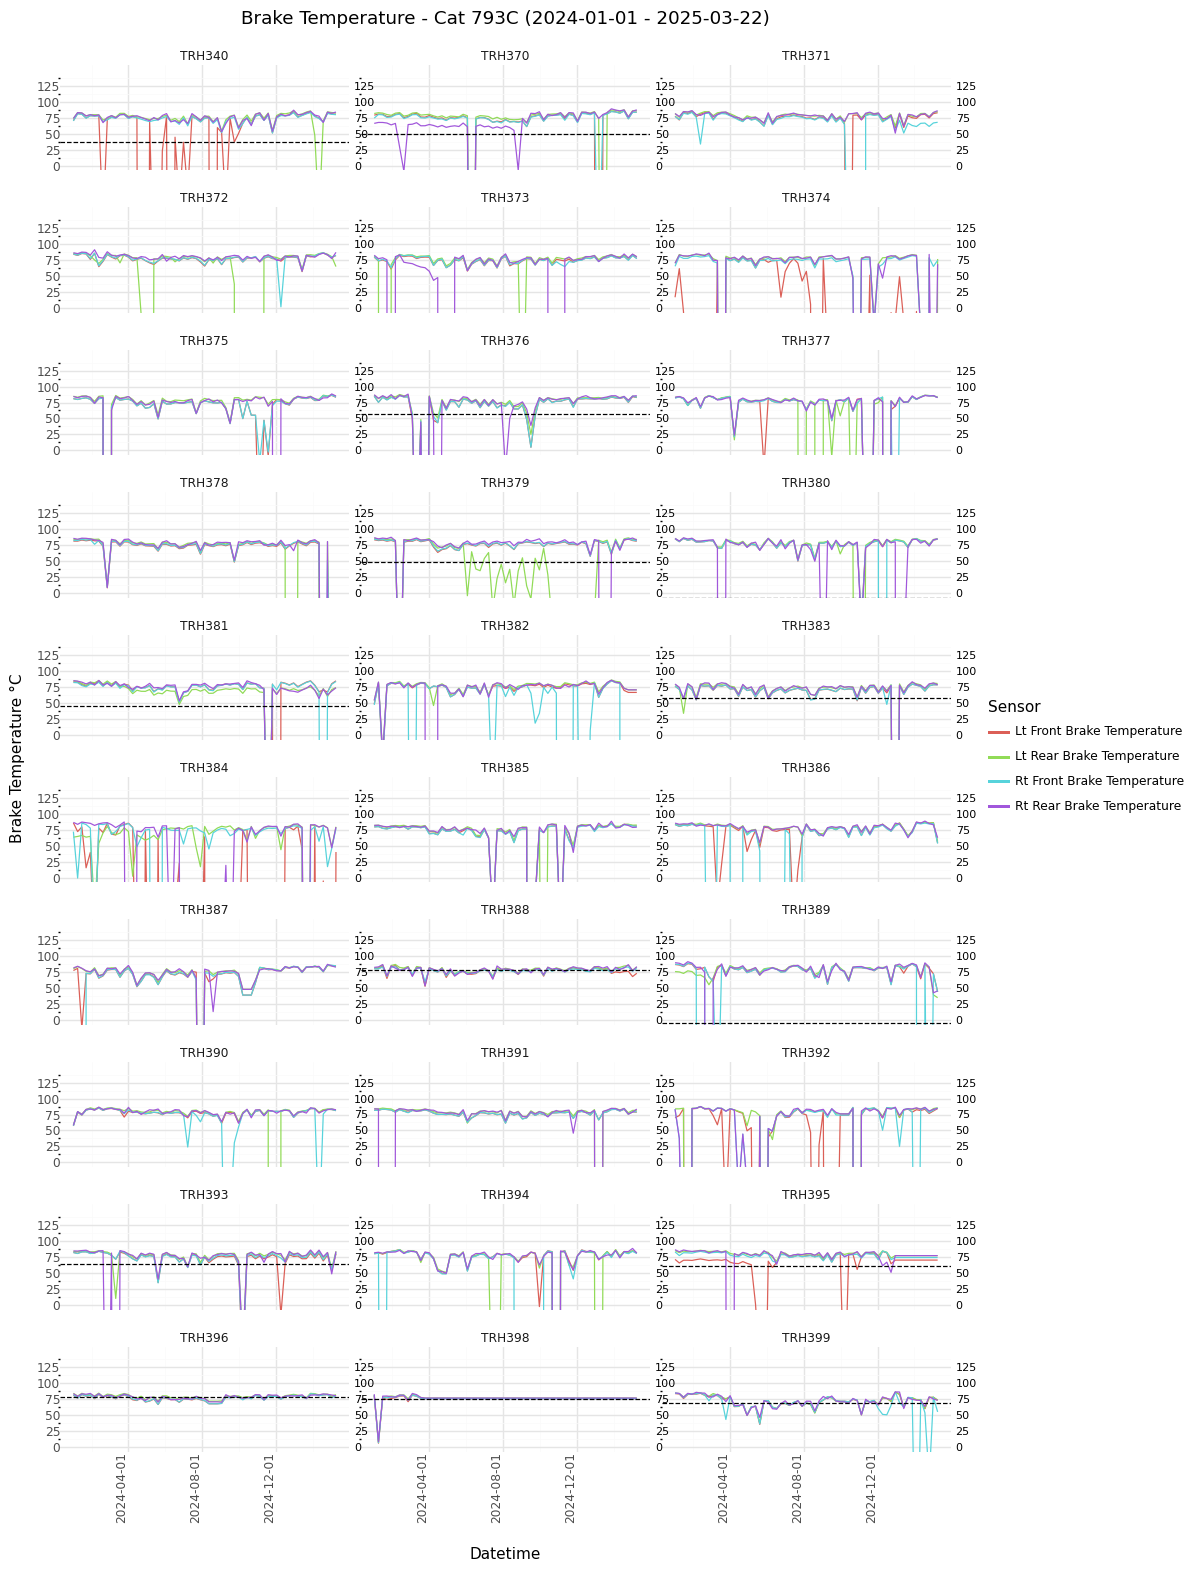

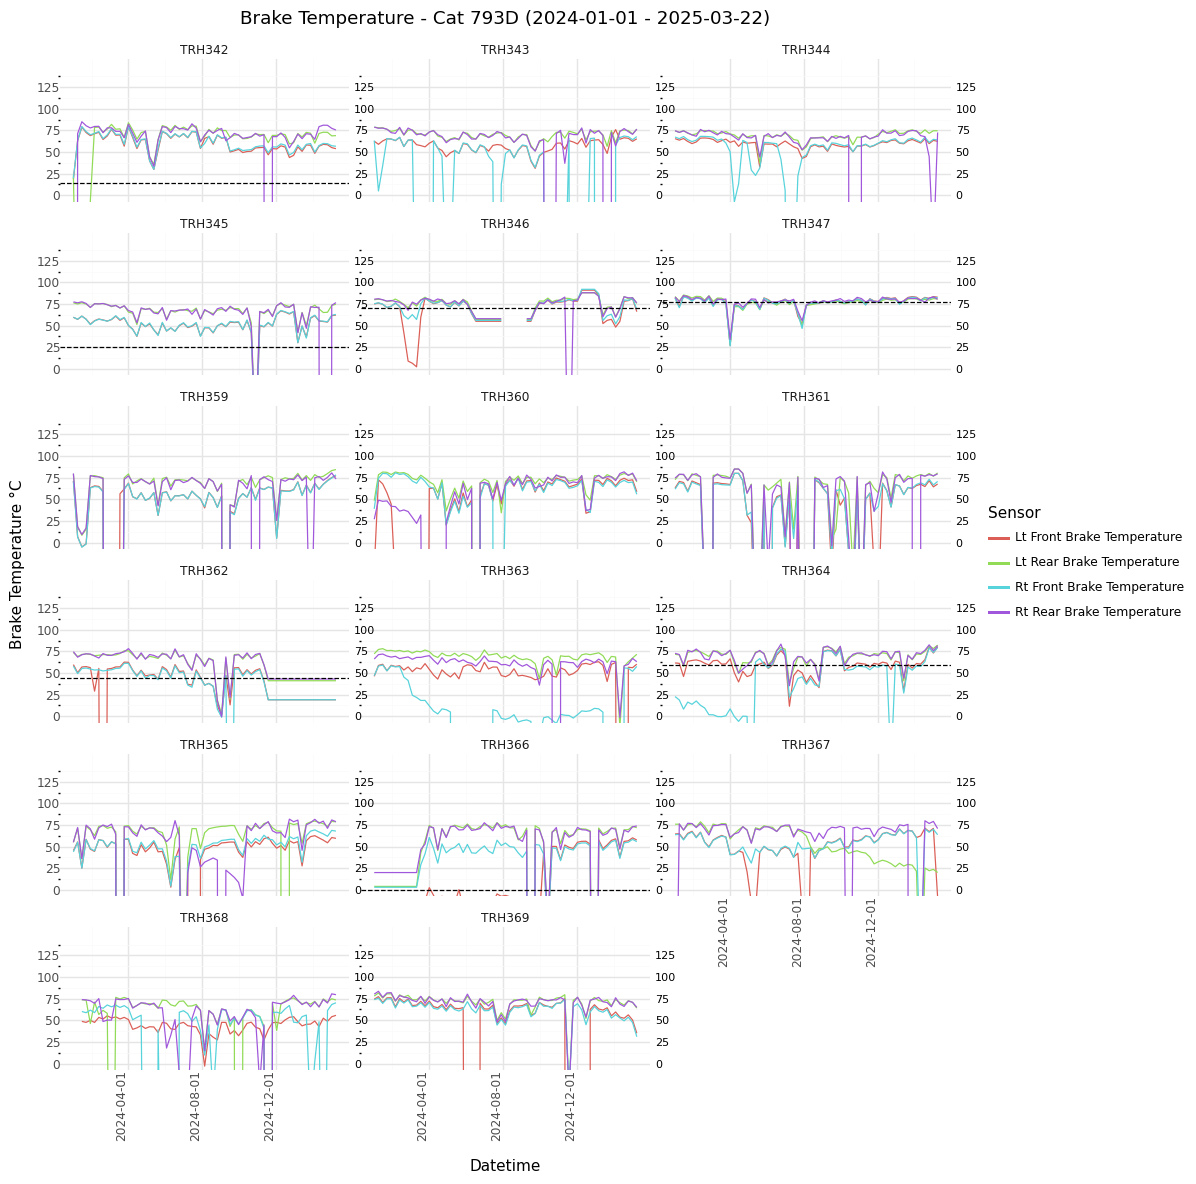

In [27]:
start_date = "2024-01-01 00:00:00"
end_date = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
week_source_df = aggregate_data(source_df, "week")
show_mean = True
y_breaks = [0, 25, 50, 75, 100, 125]
returned_figures = execute_brake_temperature(week_source_df, df_equipments, start_date, end_date, show_mean, y_breaks)
for fig in returned_figures:
    display(fig)

### Monthly Trend

StatementMeta(, 0420fb93-fb9a-4e39-8a5f-95309296ae9f, 30, Finished, Available, Finished)

Class Type: Cat 793C
Total rows: 1800
Class Type: Cat 793D
Total rows: 1020


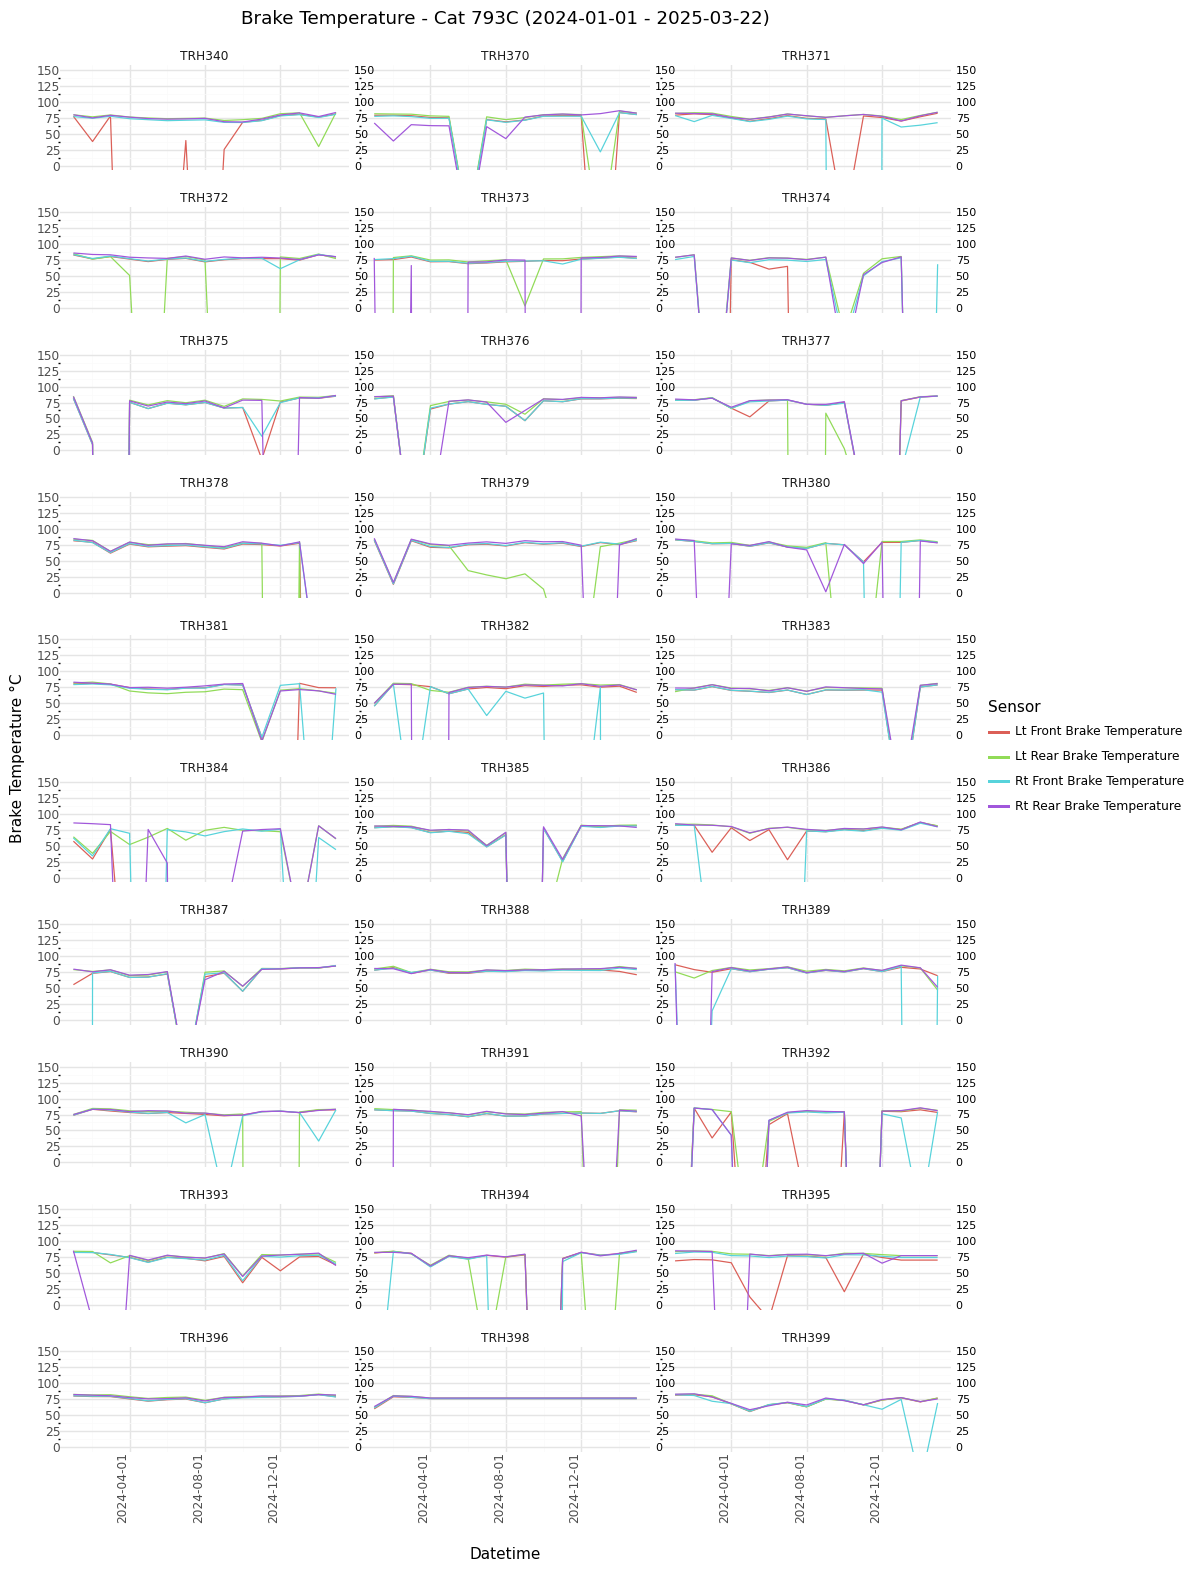

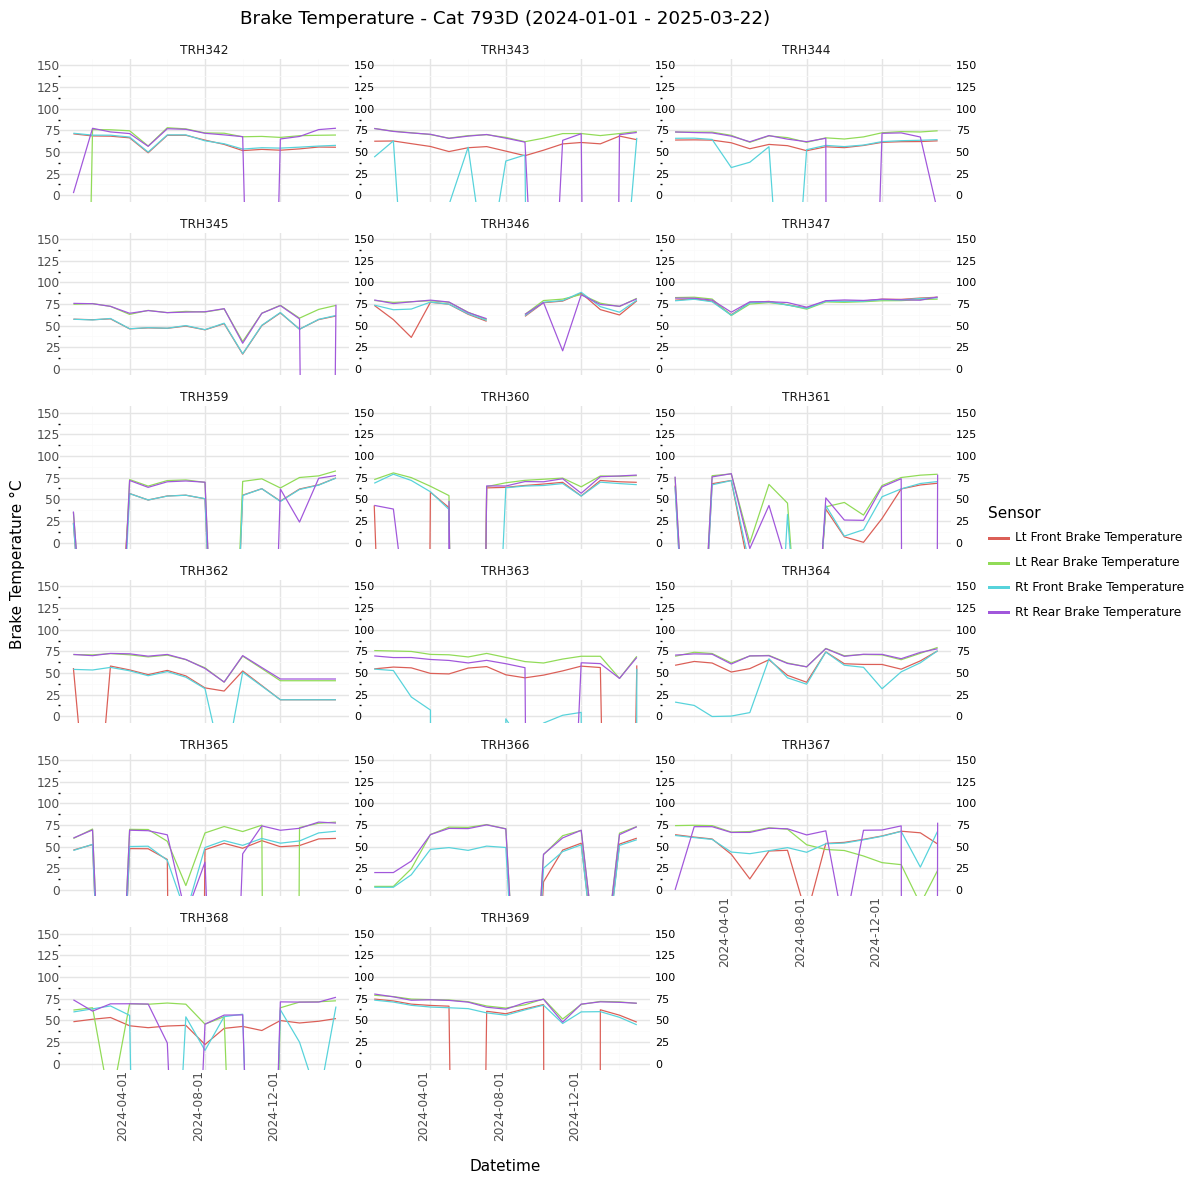

In [28]:
start_date = "2024-01-01 00:00:00"
end_date = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
month_source_df = aggregate_data(source_df, "month")
show_mean = False
y_breaks = [0, 25, 50, 75, 100, 125, 150]
returned_figures = execute_brake_temperature(month_source_df, df_equipments, start_date, end_date, show_mean, y_breaks)
for fig in returned_figures:
    display(fig)

# Test Code

In [5]:
df_filtered = source_df.filter(
    (col("Nombre_Camion").isin(["TRH380", "TRH342", "TRH343", "TRH361", "TRH362", "TRH363", "TRH364"])) & 
    (col("Nombre_Tag").isin(["Lt Front Brake Temperature","Lt Rear Brake Temperature","Rt Front Brake Temperature","Rt Rear Brake Temperature"])) & 
    (col("Fecha_Hora").between("2025-01-01 00:00:00", "2025-01-15 00:00:00")) 
)
source_pandas_df = df_filtered.toPandas()
dataset = source_pandas_df[["Fecha_Hora", "Nombre_Camion", "Nombre_Tag", "Valor"]]
dataset.columns = ["Datetime", "Equipment", "Sensor", "Value"]
original_dataset = dataset.copy()
# Remove NaN values and filter out values 
dataset = dataset.dropna(subset=["Value"])  # Remove NaN
dataset = dataset[(dataset["Value"] >= 0) & (dataset["Value"] <= 200)]  # Keep values
mean_values = dataset.groupby("Equipment")["Value"].mean().reset_index()
mean_values.rename(columns={"Value": "Mean_Value"}, inplace=True)

dataset = dataset.merge(mean_values, on="Equipment", how="left")
# Compute summary statistics per Equipment (like the R group_by + summarise)
row_count = len(dataset)
print(f"Total rows: {row_count}")
display(dataset)

StatementMeta(, 7235e079-2fb9-4e0a-8a7a-8499a6a88495, 7, Finished, Available, Finished)

Total rows: 554477


SynapseWidget(Synapse.DataFrame, d0b95338-66e8-4628-91d9-5038d6a5150b)

StatementMeta(, 7235e079-2fb9-4e0a-8a7a-8499a6a88495, 8, Finished, Available, Finished)

/home/trusted-service-user/cluster-env/trident_env/lib/python3.11/site-packages/mizani/breaks.py:448: FutureWarning: Passing the width as the parameter has been deprecated and will not work in a future version. Use breaks_date(width="4 years")


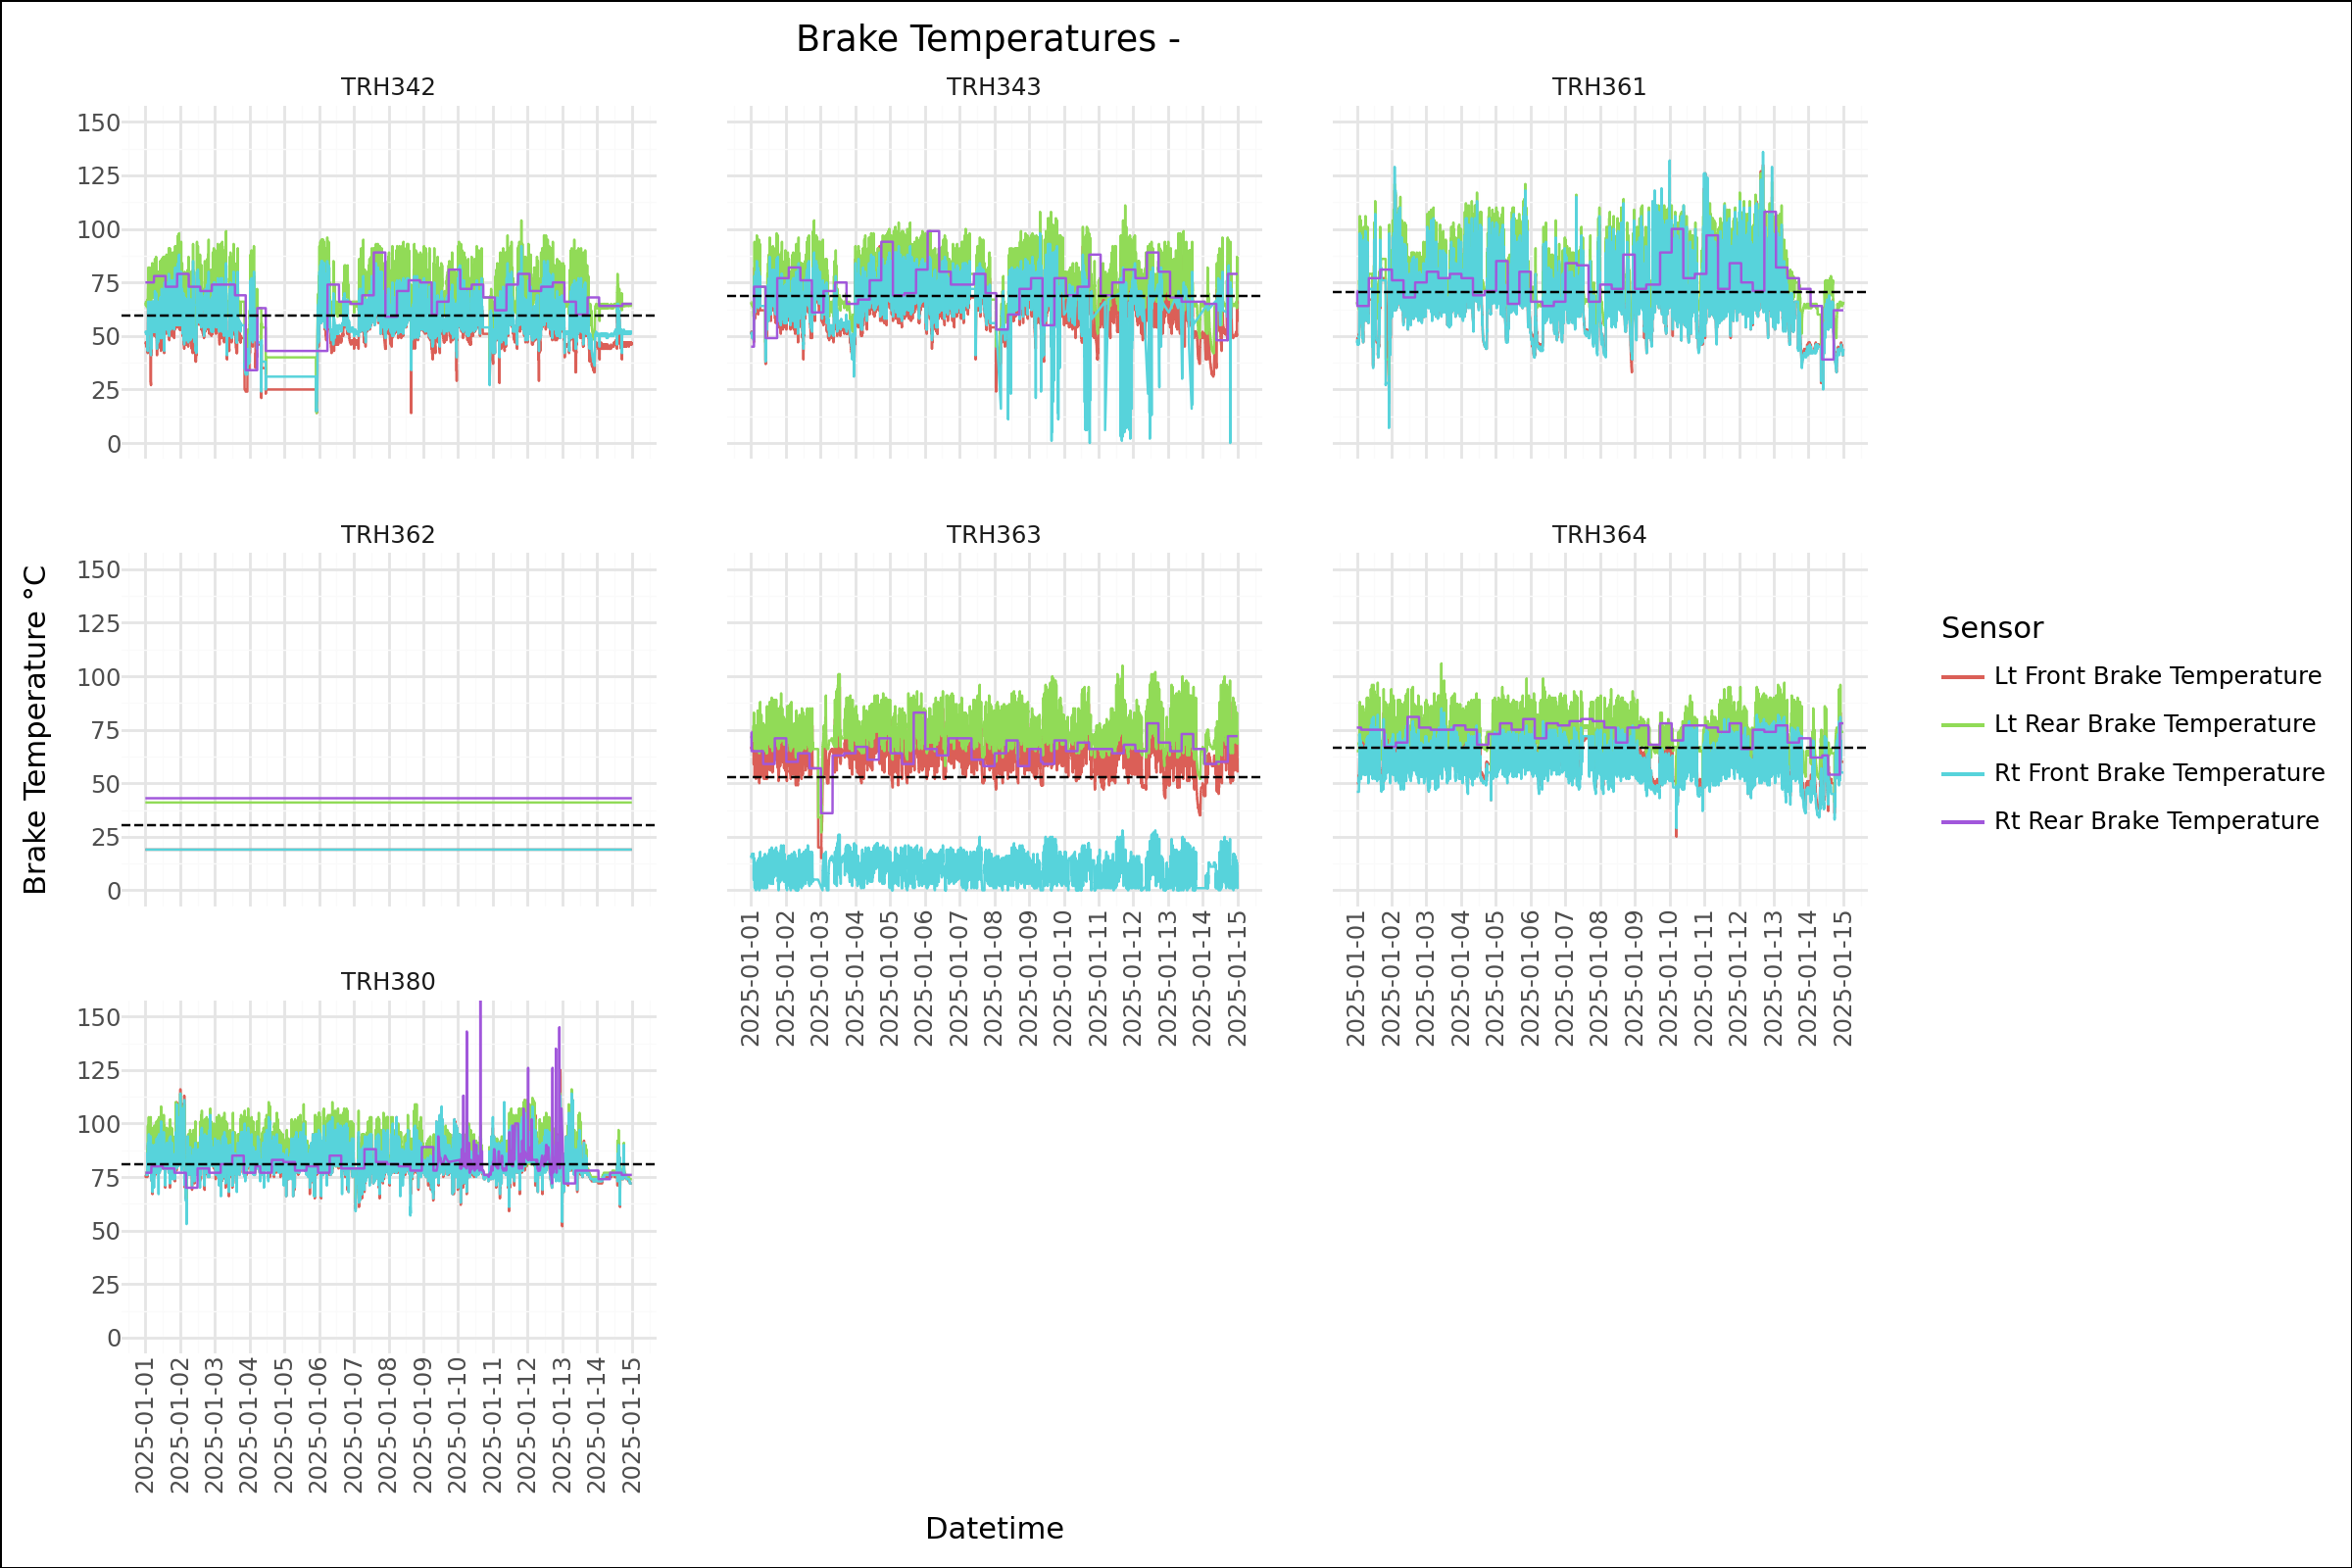

In [6]:
show_mean = True
line_chart = (
    ggplot(dataset, aes(x="Datetime", y="Value", color="Sensor"))
    + geom_line()
    # facet_wrap to create separate subplots for each truck
    + facet_wrap("~Equipment", ncol=3)  # one column, two rows
    + scale_x_datetime(date_breaks="1 day", date_labels="%Y-%m-%d")  # Show all days
    + scale_y_continuous(
        breaks=[0, 25, 50, 75, 100, 125, 150]
    )
    + coord_cartesian(ylim=(0, 150))  # Set y-axis limits
    + theme_minimal() 
    + labs(
        title=f"Brake Temperatures - ",
        x="Datetime",
        y="Brake Temperature °C"
    )
    + theme(
        panel_spacing=0.03,
        figure_size=(12, 8),  # Adjust overall figure size as needed
        axis_text_x=element_text(rotation=90),
        panel_background=element_rect(fill="white"),
        plot_background=element_rect(fill="white"),
    )
)
# Add mean line only if show_mean is True
if show_mean:
    line_chart += geom_hline(aes(yintercept="Mean_Value"), dataset, color="black", linetype="dashed")

line_chart

StatementMeta(, 7235e079-2fb9-4e0a-8a7a-8499a6a88495, 10, Finished, Available, Finished)

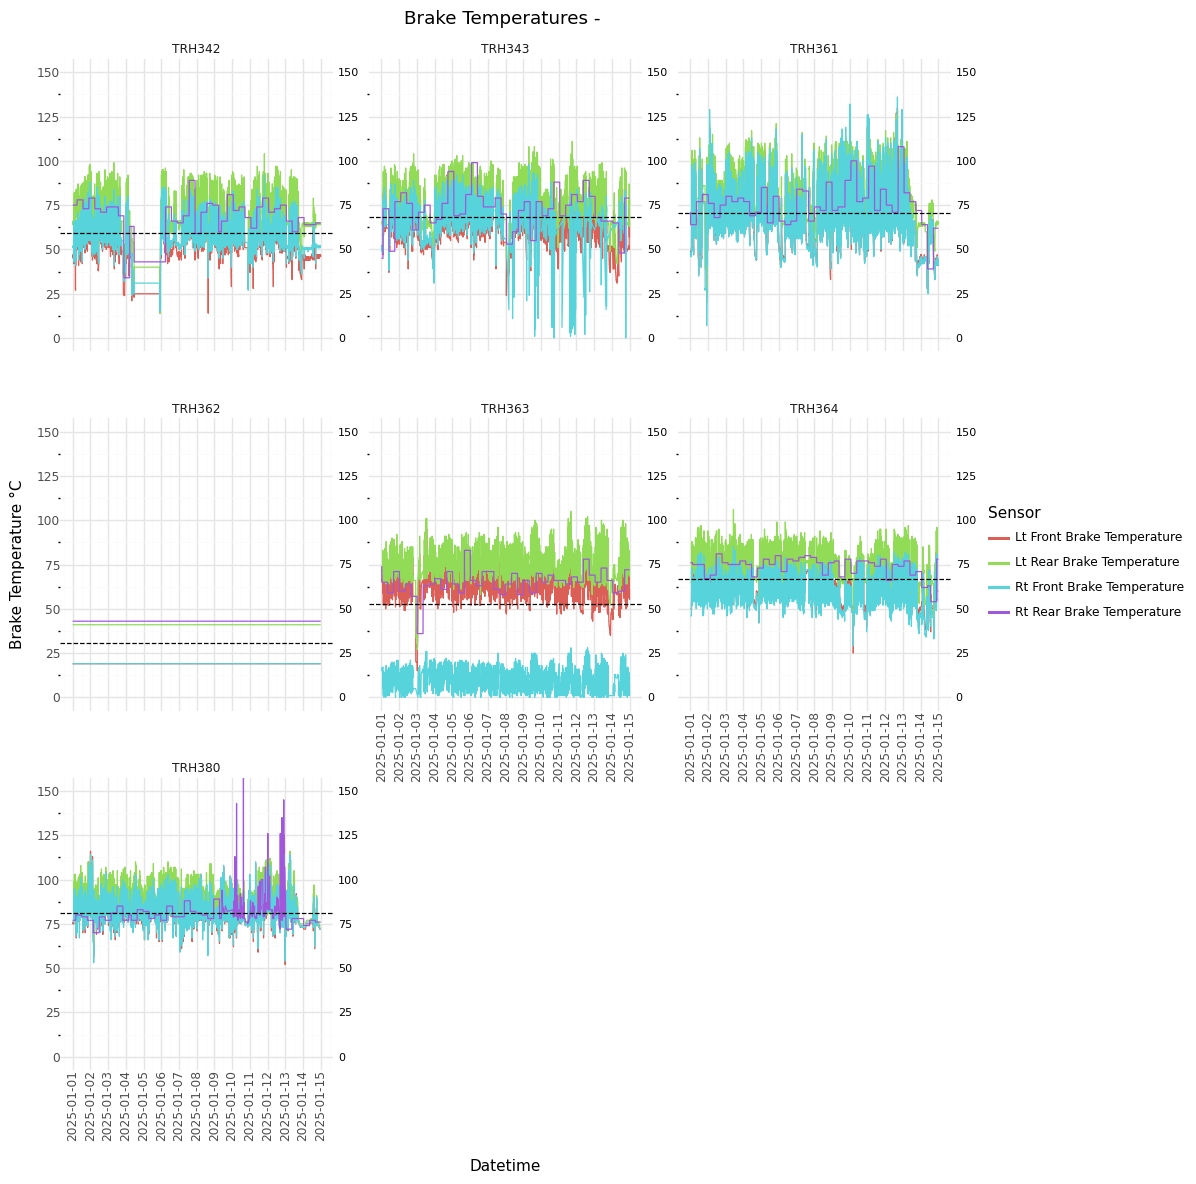

In [8]:
fig = line_chart.draw()
fig.patch.set_visible(False)
orig_width, orig_height = fig.get_size_inches()
new_height = orig_height * 1.5
fig.set_size_inches(orig_width, new_height)
fig.patch.set_facecolor('white')

# Loop over all axes in the figure (each facet is its own Axes)
for ax in fig.axes:
    ax.set_facecolor('white')
    # Create a twin y-axis sharing the same x-axis
    ax2 = ax.twinx()
    # Set the twin y-axis limits to match the primary y-axis
    ax2.set_ylim(ax.get_ylim())
    # Set the ticks you desire for the secondary y-axis
    ax2.set_yticks([0, 25, 50, 75, 100, 125, 150])
    # Style secondary y-axis
    ax2.tick_params(axis='y', labelsize=8)  # Font size 8
    # Remove borders from both axes
    for spine in ax.spines.values():
        spine.set_visible(False)
    for spine in ax2.spines.values():
        spine.set_visible(False)
    ax.tick_params(length=0)
    ax2.tick_params(length=0)

fig
#fig.save(f"/lakehouse/default/Files/Images/Linechart_Test.png", width=16, height=16, dpi=400)
#fig.savefig("/lakehouse/default/Files/Images/Linechart_Test.jpeg", dpi=400, facecolor='white')

### Code to delete files

In [14]:
import glob
import os

folder_path = "/lakehouse/default/Files/Images/*"  # Add /* to target all files
for file in glob.glob(folder_path):
    if os.path.isfile(file):  # Ensure it's a file, not a directory
        os.remove(file)  # Delete the file

StatementMeta(, 8f4611fa-42b3-4a4c-85f7-62a558049707, 16, Finished, Available, Finished)